# Objetivos 1 y 2

## Objetivo 1: Simular la amortización con el sistema francés y el alemnán, y elegir con cuál elegimos


Cargamos todas las librerías necesarias

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display


Leemos el CSV que hemos filtrado previamente

In [2]:

ruta_csv = r"C:\Users\Álvaro\Downloads\Prestamos_educacion_limpio.csv"

df = pd.read_csv(ruta_csv)

In [3]:
pd.set_option("display.max_columns", None)
df

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,Posesion_Hipoteca,Personas_Cargo,Fiador,Impago,Prima,Estudios_encoded,Estado_Civil_Divorciado,Estado_Civil_Soltero,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Jornada completa,Tipo_Jornada_Laboral_Tiempo parcial
0,KG9CT9,34,56572,73978,763,86,1,13.91,60,0.55,0,0,0,0,800.00,2,0,1,0,0,1
1,V5O0K9,37,68698,150000,824,162,2,10.53,24,0.37,1,0,0,0,580.00,2,0,0,0,1,0
2,YE5GD0,40,50000,7490,671,167,2,9.24,60,0.10,1,1,0,0,130.00,1,0,0,0,0,0
3,Q6HQ3D,38,63033,11801,649,196,1,7.63,48,0.10,0,1,0,0,168.08,1,0,1,0,0,1
4,XO8CO4,19,22301,40000,788,17,4,8.40,36,0.50,1,1,1,0,293.94,0,0,1,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
178603,VLZOS9,43,42597,138502,733,221,2,12.72,36,0.55,1,0,0,0,760.00,1,1,0,0,1,0
178604,Z0BY9Y,42,38082,40000,567,326,3,9.50,36,0.45,0,0,0,1,542.47,0,0,0,0,1,0
178605,ARBQ2V,41,41211,9973,507,272,3,7.34,60,0.10,0,1,0,0,188.19,1,0,0,0,0,1
178606,1LVUEW,48,35469,22481,783,392,2,16.34,12,0.20,0,0,1,0,58.46,0,0,1,0,0,1


Ingresos: Ingreso anual. 

Ratio_Deuda_Ingresos: Pagos mensuales de deuda / Ingresos mensuales

Posesion_Hipoteca: 1 = sí y 0 = no; se usa para formar la situación de vivienda.

Edad: se usa junto con la hipoteca para aplicar la hipótesis de vivienda acordada.

Monto_Inicial, Ratio_Interes y Duracion: se usan para calcular las cuotas.

### Creamos la variable de situación vivienda

Sin hipoteca y con más de 60 años, suponemos que no paga vivienda

Sin hipoteca y hasta 60 años, suponemos alquiler

Con hipoteca, clasificamos la situación como hipoteca

In [4]:
df["Situacion_vivienda"] = "Alquiler asumido"
df.loc[df["Posesion_Hipoteca"] == 1, "Situacion_vivienda"] = "Hipoteca"
df.loc[
    (df["Edad"] > 60) & (df["Posesion_Hipoteca"] == 0),
    "Situacion_vivienda"
] = "Sin pago de vivienda asumido"

display(df["Situacion_vivienda"].value_counts())

Situacion_vivienda
Alquiler asumido                114064
Hipoteca                         62330
Sin pago de vivienda asumido      2214
Name: count, dtype: int64

### Calculamos las cuotas

In [5]:
df[["Monto_Inicial", "Ratio_Interes", "Duracion"]].head(10)

,Monto_Inicial,Ratio_Interes,Duracion
0,73978,13.91,60
1,150000,10.53,24
2,7490,9.24,60
3,11801,7.63,48
4,40000,8.40,36
5,4140,10.73,36
6,5718,7.63,48
7,10000,13.65,12
8,21366,9.26,36
9,40000,9.28,24


Observamos que el interes está en porcentajes por lo que lo en la función lo vamos a pasar a números decimales

In [6]:
def cuota_francesa(fila):
    capital = fila["Monto_Inicial"]
    interes = fila["Ratio_Interes"] / 100 / 12
    meses = fila["Duracion"]
    if interes == 0:
        return capital / meses
    return capital * interes / (1 - (1 + interes) ** (-meses))

df["Cuota_francesa"] = df.apply(cuota_francesa, axis=1)

Hemos creado la función que calcula la amortización de la capitalización francesa y hemos creado una columna que se llama cuota francesa

Llamamos a la función para observar las distintas columnas

In [7]:
df

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,Posesion_Hipoteca,Personas_Cargo,Fiador,Impago,Prima,Estudios_encoded,Estado_Civil_Divorciado,Estado_Civil_Soltero,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Jornada completa,Tipo_Jornada_Laboral_Tiempo parcial,Situacion_vivienda,Cuota_francesa
0,KG9CT9,34,56572,73978,763,86,1,13.91,60,0.55,0,0,0,0,800.00,2,0,1,0,0,1,Alquiler asumido,1717.888844
1,V5O0K9,37,68698,150000,824,162,2,10.53,24,0.37,1,0,0,0,580.00,2,0,0,0,1,0,Hipoteca,6958.489534
2,YE5GD0,40,50000,7490,671,167,2,9.24,60,0.10,1,1,0,0,130.00,1,0,0,0,0,0,Hipoteca,156.353964
3,Q6HQ3D,38,63033,11801,649,196,1,7.63,48,0.10,0,1,0,0,168.08,1,0,1,0,0,1,Alquiler asumido,286.051711
4,XO8CO4,19,22301,40000,788,17,4,8.40,36,0.50,1,1,1,0,293.94,0,0,1,0,1,0,Hipoteca,1260.848845
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
178603,VLZOS9,43,42597,138502,733,221,2,12.72,36,0.55,1,0,0,0,760.00,1,1,0,0,1,0,Hipoteca,4648.022522
178604,Z0BY9Y,42,38082,40000,567,326,3,9.50,36,0.45,0,0,0,1,542.47,0,0,0,0,1,0,Alquiler asumido,1281.317990
178605,ARBQ2V,41,41211,9973,507,272,3,7.34,60,0.10,0,1,0,0,188.19,1,0,0,0,0,1,Alquiler asumido,199.081065
178606,1LVUEW,48,35469,22481,783,392,2,16.34,12,0.20,0,0,1,0,58.46,0,0,1,0,0,1,Alquiler asumido,2043.339245


In [8]:
def primera_cuota_alemana(fila):
    capital = fila["Monto_Inicial"]
    interes = fila["Ratio_Interes"] / 100 / 12
    meses = fila["Duracion"]

    amortizacion = capital / meses
    intereses = capital * interes
    cuota = amortizacion + intereses

    return cuota


df["Cuota_alemana_inicial"] = df.apply(primera_cuota_alemana, axis=1)


In [9]:
df

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,Posesion_Hipoteca,Personas_Cargo,Fiador,Impago,Prima,Estudios_encoded,Estado_Civil_Divorciado,Estado_Civil_Soltero,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Jornada completa,Tipo_Jornada_Laboral_Tiempo parcial,Situacion_vivienda,Cuota_francesa,Cuota_alemana_inicial
0,KG9CT9,34,56572,73978,763,86,1,13.91,60,0.55,0,0,0,0,800.00,2,0,1,0,0,1,Alquiler asumido,1717.888844,2090.494983
1,V5O0K9,37,68698,150000,824,162,2,10.53,24,0.37,1,0,0,0,580.00,2,0,0,0,1,0,Hipoteca,6958.489534,7566.250000
2,YE5GD0,40,50000,7490,671,167,2,9.24,60,0.10,1,1,0,0,130.00,1,0,0,0,0,0,Hipoteca,156.353964,182.506333
3,Q6HQ3D,38,63033,11801,649,196,1,7.63,48,0.10,0,1,0,0,168.08,1,0,1,0,0,1,Alquiler asumido,286.051711,320.888858
4,XO8CO4,19,22301,40000,788,17,4,8.40,36,0.50,1,1,1,0,293.94,0,0,1,0,1,0,Hipoteca,1260.848845,1391.111111
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
178603,VLZOS9,43,42597,138502,733,221,2,12.72,36,0.55,1,0,0,0,760.00,1,1,0,0,1,0,Hipoteca,4648.022522,5315.398978
178604,Z0BY9Y,42,38082,40000,567,326,3,9.50,36,0.45,0,0,0,1,542.47,0,0,0,0,1,0,Alquiler asumido,1281.317990,1427.777778
178605,ARBQ2V,41,41211,9973,507,272,3,7.34,60,0.10,0,1,0,0,188.19,1,0,0,0,0,1,Alquiler asumido,199.081065,227.218183
178606,1LVUEW,48,35469,22481,783,392,2,16.34,12,0.20,0,0,1,0,58.46,0,0,1,0,0,1,Alquiler asumido,2043.339245,2179.532950


Para decidir qué sistema de amortización elegir, nos apoyaremos en dos variables. La primera es Ratio_Deuda_Ingresos, que indica cuánta deuda tiene el prestatario en relación con lo que gana. La segunda la crearemos nosotros: dividiremos la cuota del sistema alemán entre los ingresos mensuales del cliente, para ver qué parte de su sueldo se le iría en pagarla.

In [10]:
df["Ingresos_mensuales"] = df["Ingresos"] / 12

display(df[["Ingresos", "Ingresos_mensuales"]].head())


,Ingresos,Ingresos_mensuales
0,56572,4714.333333
1,68698,5724.833333
2,50000,4166.666667
3,63033,5252.750000
4,22301,1858.416667


Los ingresos mensuales se calculan dividiendo Ingresos (que es el ingreso anual) entre 12, porque la cuota del préstamo se paga 12 veces al año. Así obtenemos el ingreso medio mensual del cliente, que es con lo que se debe comparar la cuota.

### Ratio de la primera cuota alemana

Dividimos la primera cuota alemana entre los ingresos calculados. El resultado indica qué parte de esos ingresos representa la nueva cuota. Cuanto mayor sea el valor de la columna "Ratio_aleman" mayor esfuerzo tendrá que hacer el cliente.


In [11]:
df["Ratio_aleman"] = df["Cuota_alemana_inicial"] / df["Ingresos_mensuales"]

display(df[["Cuota_alemana_inicial", "Ingresos_mensuales", "Ratio_aleman"]].head().round(3))


,Cuota_alemana_inicial,Ingresos_mensuales,Ratio_aleman
0,2090.495,4714.333,0.443
1,7566.250,5724.833,1.322
2,182.506,4166.667,0.044
3,320.889,5252.750,0.061
4,1391.111,1858.417,0.749


In [12]:
df["Ratio_aleman"].describe()

count    178608.000000
mean          0.555387
std           0.597316
min           0.014084
25%           0.177722
50%           0.359980
75%           0.716140
max           9.841314
Name: Ratio_aleman, dtype: float64

Para estimar el endeudamiento total del cliente si el préstamo se amortizara con el sistema alemán, sumaremos dos ratios: el DTI (Ratio_Deuda_Ingresos), que recoge lo que ya debe en relación con sus ingresos, y el ratio alemán, que mide el peso de la primera cuota del nuevo préstamo sobre esos ingresos. Sumarlos tiene sentido porque los dos expresan una deuda como proporción de los ingresos.

#### Ratio de deuda ingresos = Pagos mensuales de deuda / Ingresos mensuales



#### Ratio Aleman = Cuota Alemana/ Ingresos mensuales

Aplicamos la fórmula, tanto para el alemán como para el frances

In [13]:
df["Ratio_Deuda_Ingresos_Aleman"] = (
    df["Ratio_aleman"] + df["Ratio_Deuda_Ingresos"]
)

df["Ratio_frances"] = df["Cuota_francesa"] / df["Ingresos_mensuales"]
df["Ratio_Deuda_Ingresos_Frances"] = (
    df["Ratio_frances"] + df["Ratio_Deuda_Ingresos"]
)

display(df[[
    "Ratio_Deuda_Ingresos",
    "Ratio_aleman",
    "Ratio_Deuda_Ingresos_Aleman",
    "Ratio_Deuda_Ingresos_Frances"
]].head().round(3))


,Ratio_Deuda_Ingresos,Ratio_aleman,Ratio_Deuda_Ingresos_Aleman,Ratio_Deuda_Ingresos_Frances
0,0.55,0.443,0.993,0.914
1,0.37,1.322,1.692,1.585
2,0.10,0.044,0.144,0.138
3,0.10,0.061,0.161,0.154
4,0.50,0.749,1.249,1.178


Primero comprobamos si el sistema alemán cumple el límite. Si no lo cumple, miramos el francés como alternativa. Si, incluso con la cuota francesa, las deudas superan los ingresos mensuales, el préstamo se marca como «No viable». 

### Elegir el sistema de amortización

Para elegir el sistema, usamos estos límites:

- Sin gastos de vivienda: 40%.
- Con hipoteca: 35%, siguiendo la referencia del Banco de España.
- Con alquiler: 30%, como supuesto de nuestro trabajo. No es un límite oficial.

El 40% y la referencia de la hipoteca se basan en el Banco de España. El 30% del alquiler lo hemos elegido para tener en cuenta ese gasto.


In [14]:
df["Limite_liquidez"] = 0.40
df.loc[df["Situacion_vivienda"] == "Hipoteca", "Limite_liquidez"] = 0.35
df.loc[df["Situacion_vivienda"] == "Alquiler asumido", "Limite_liquidez"] = 0.30

df["Sistema_Elegido"] = np.where(
    df["Ratio_Deuda_Ingresos_Aleman"] > df["Limite_liquidez"],
    "Francés",
    "Alemán"
)

df["Justificacion"] = np.where(
    df["Ratio_Deuda_Ingresos_Aleman"] > df["Limite_liquidez"],
    "Francés: el ratio alemán supera el límite de su vivienda.",
    "Alemán: el ratio alemán queda dentro del límite de su vivienda."
)

display(df["Sistema_Elegido"].value_counts())


Sistema_Elegido
Francés    138720
Alemán      39888
Name: count, dtype: int64

In [15]:
conteo = df["Sistema_Elegido"].value_counts()
porcentaje = conteo / len(df) * 100
resumen = pd.DataFrame({"Préstamos": conteo, "Porcentaje": porcentaje})
display(resumen.round(2))


,Préstamos,Porcentaje
Sistema_Elegido,,
Francés,138720,77.67
Alemán,39888,22.33


Los resultados tienen sentido porque la cuota inicial alemana suele ser más alta. Por eso, en más casos se supera el límite de endeudamiento y se acaba eligiendo el sistema francés. Esto explica que el francés se asigne al 77,67 % de los préstamos y el alemán al 22,33 %.

### Cálculo del VAN y la TIR

Primero defino el cuadro de amortización

In [16]:
def cuadro_amortizacion(fila, sistema):
    capital = float(fila["Monto_Inicial"])
    interes = float(fila["Ratio_Interes"]) / 100 / 12
    meses = int(fila["Duracion"])
    saldo = capital
    filas = []

    if sistema == "Francés":
        cuota_fija = float(fila["Cuota_francesa"])
    else:
        amortizacion_fija = capital / meses

    for mes in range(1, meses + 1):
        saldo_inicial = saldo
        intereses = saldo_inicial * interes

        if sistema == "Francés":
            amortizacion = cuota_fija - intereses
        else:
            amortizacion = amortizacion_fija

        if mes == meses:
            amortizacion = saldo_inicial

        cuota = amortizacion + intereses
        saldo = max(saldo_inicial - amortizacion, 0)
        filas.append([mes, saldo_inicial, amortizacion, intereses, cuota, saldo])

    return pd.DataFrame(
        filas,
        columns=[
            "Periodo", "Saldo_Inicial", "Amortizacion",
            "Intereses", "Cuota", "Saldo_Pendiente"
        ]
    )

Calculamos el VAN y la TIR para comparar los sistemas francés y alemán con el mismo préstamo. El VAN tiene en cuenta el dinero que se presta al principio y las cuotas que se cobran después. La TIR indica la rentabilidad del préstamo.

Hemos supuesto una tasa de descuento anual del 10 % porque necesitamos una tasa para calcular el VAN. Para el cálculo mensual, hemos dividido el 10 % entre 12.

In [17]:
def calcular_van(flujos, k):
    van = 0
    for t, flujo in enumerate(flujos):
        van += flujo / (1 + k) ** t
    return van


def calcular_tir(flujos):
    k1 = 0.0
    k2 = 0.05

    van1 = calcular_van(flujos, k1)
    van2 = calcular_van(flujos, k2)

    # Buscamos dos tasas con VAN de distinto signo
    while van2 > 0:
        k2 *= 2
        van2 = calcular_van(flujos, k2)

    # Aplicamos la interpolación de las diapositivas
    for _ in range(100):
        tir = k1 + (van1 / (van1 - van2)) * (k2 - k1)
        van_tir = calcular_van(flujos, tir)

        if abs(van_tir) < 0.01:
            return tir

        if van_tir > 0:
            k1, van1 = tir, van_tir
        else:
            k2, van2 = tir, van_tir

    return tir


prestamo = df.iloc[0]
k_mensual = 0.10 / 12  # 10 % anual supuesto, pasado a meses
resultados = []

for sistema in ["Francés", "Alemán"]:
    cuadro = cuadro_amortizacion(prestamo, sistema)
    flujos = [-prestamo["Monto_Inicial"]] + cuadro["Cuota"].tolist()

    van = calcular_van(flujos, k_mensual)
    tir_mensual = calcular_tir(flujos)

    resultados.append({
        "Sistema": sistema,
        "VAN (€)": van,
        "TIR mensual (%)": tir_mensual * 100,
        "TIR anual efectiva (%)": ((1 + tir_mensual) ** 12 - 1) * 100
    })

display(pd.DataFrame(resultados).round(2))

,Sistema,VAN (€),TIR mensual (%),TIR anual efectiva (%)
0,Francés,6875.07,1.16,14.83
1,Alemán,6235.66,1.16,14.83


#### Interpretación del VAN y la TIR

Para este préstamo de ejemplo, los dos sistemas tienen un VAN positivo usando la tasa de descuento anual del 10 % que hemos supuesto. Desde el punto de vista de la entidad, esto significa que el valor actual de las cuotas supera el capital prestado.

El VAN francés es de 6.875,07 € y el alemán de 6.235,66 €. En este caso, el francés queda 639,41 € por encima. La TIR es igual en ambos sistemas: 1,16 % mensual, equivalente a un 14,83 % anual efectivo. Esto ocurre porque se usa el mismo préstamo y el mismo interés; lo que cambia es cómo se reparten las cuotas.

Estos resultados corresponden solo al préstamo de ejemplo, así que no significan que el sistema francés dé siempre un VAN mayor.

## Objetivo 2: Calcular el valor presente de las cuotas pendientes a mitad del préstamo

Para saber en qué momento del préstamo evaluamos las cuotas, definimos Mitad_Prestamo como el mes que está justo a la mitad de la duración total. A partir de ahí creamos Cuotas_Pendientes, que cuenta las cuotas que aún quedan por pagar en ese punto, es decir, la duración total menos las cuotas ya pagadas.

In [18]:
df["Mitad_Prestamo"] = (df["Duracion"] // 2).astype(int)
display(df["Duracion"].value_counts().sort_index())

Duracion
12    17868
24    35420
36    62552
48    35693
60    27075
Name: count, dtype: int64

Como las duraciones son pares coincden con la mitad exacta del préstamo

In [19]:
def valor_presente_mitad(fila):
    capital = fila["Monto_Inicial"]
    interes = fila["Ratio_Interes"] / 100 / 12
    meses = int(fila["Duracion"])
    pagados = int(fila["Mitad_Prestamo"])
    pendientes = meses - pagados

    if fila["Sistema_Elegido"] == "Francés":
        cuota = fila["Cuota_francesa"]
        if interes == 0:
            return cuota * pendientes
        return cuota * (1 - (1 + interes) ** (-pendientes)) / interes

    amortizacion = capital / meses
    saldo = 0
    for mes in range(pagados + 1, meses + 1):
        saldo_inicial = capital - amortizacion * (mes - 1)
        cuota = amortizacion + saldo_inicial * interes
        saldo += cuota / (1 + interes) ** (mes - pagados)
    return saldo

Calculamos cuánto valen, en la mitad del préstamo, las cuotas que le quedan por pagar a cada cliente. En el sistema francés usamos una fórmula directa, porque todas las cuotas son iguales. En el alemán usamos un bucle, porque las cuotas van bajando, y sumamos cada cuota descontada. El resultado es el saldo que le queda por pagar al cliente en la mitad del préstamo.

In [20]:
df["Saldo_Pendiente_mitad"] = df.apply(valor_presente_mitad, axis=1)

In [21]:
df = df.drop(columns=["Justificacion"], errors="ignore")
df.head(25)

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,Posesion_Hipoteca,Personas_Cargo,Fiador,Impago,Prima,Estudios_encoded,Estado_Civil_Divorciado,Estado_Civil_Soltero,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Jornada completa,Tipo_Jornada_Laboral_Tiempo parcial,Situacion_vivienda,Cuota_francesa,Cuota_alemana_inicial,Ingresos_mensuales,Ratio_aleman,Ratio_Deuda_Ingresos_Aleman,Ratio_frances,Ratio_Deuda_Ingresos_Frances,Limite_liquidez,Sistema_Elegido,Mitad_Prestamo,Saldo_Pendiente_mitad
0,KG9CT9,34,56572,73978,763,86,1,13.91,60,0.55,0,0,0,0,800.00,2,0,1,0,0,1,Alquiler asumido,1717.888844,2090.494983,4714.333333,0.443434,0.993434,0.364397,0.914397,0.30,Francés,30,43320.523459
1,V5O0K9,37,68698,150000,824,162,2,10.53,24,0.37,1,0,0,0,580.00,2,0,0,0,1,0,Hipoteca,6958.489534,7566.250000,5724.833333,1.321654,1.691654,1.215492,1.585492,0.35,Francés,12,78927.928367
2,YE5GD0,40,50000,7490,671,167,2,9.24,60,0.10,1,1,0,0,130.00,1,0,0,0,0,0,Hipoteca,156.353964,182.506333,4166.666667,0.043802,0.143802,0.037525,0.137525,0.35,Alemán,30,3745.000000
3,Q6HQ3D,38,63033,11801,649,196,1,7.63,48,0.10,0,1,0,0,168.08,1,0,1,0,0,1,Alquiler asumido,286.051711,320.888858,5252.750000,0.061090,0.161090,0.054458,0.154458,0.30,Alemán,24,5900.500000
4,XO8CO4,19,22301,40000,788,17,4,8.40,36,0.50,1,1,1,0,293.94,0,0,1,0,1,0,Hipoteca,1260.848845,1391.111111,1858.416667,0.748546,1.248546,0.678453,1.178453,0.35,Francés,18,21253.963451
5,Z2J6Q9,35,30293,4140,686,154,3,10.73,36,0.15,0,1,0,0,46.21,0,0,1,0,1,0,Alquiler asumido,135.009553,152.018500,2524.416667,0.060219,0.210219,0.053481,0.203481,0.30,Alemán,18,2070.000000
6,VYADPM,49,34325,5718,703,357,2,7.63,48,0.17,1,0,1,0,35.19,0,0,0,0,1,0,Hipoteca,138.602125,155.481950,2860.416667,0.054356,0.224356,0.048455,0.218455,0.35,Alemán,24,2859.000000
7,YBJXM9,22,18894,10000,549,29,1,13.65,12,0.12,0,0,0,0,64.69,0,0,1,1,0,0,Alquiler asumido,896.225190,947.083333,1574.500000,0.601514,0.721514,0.569213,0.689213,0.30,Francés,6,5169.596781
8,JGC3OU,40,40803,21366,702,269,1,9.26,36,0.15,0,0,1,0,162.63,0,1,0,1,0,0,Alquiler asumido,682.021482,758.374300,3400.250000,0.223035,0.373035,0.200580,0.350580,0.30,Francés,18,11420.909441
9,ZLA6OV,35,47672,40000,825,142,2,9.28,24,0.24,1,0,0,0,142.05,1,0,0,0,0,0,Hipoteca,1832.532741,1976.000000,3972.666667,0.497399,0.737399,0.461285,0.701285,0.35,Francés,12,20923.772362


### Comprobar el saldo con los cuadros completos

Comparamos el saldo después de pagar la cuota de la mitad con el valor presente calculado arriba, con los cuadros de amortización creados ya previamente

Cogemos un préstamo con el sistema frances y otro con el alemán para poder crear los cuadros. 

In [22]:

ejemplo_frances = df[df["Sistema_Elegido"] == "Francés"].iloc[0]
ejemplo_aleman = df[df["Sistema_Elegido"] == "Alemán"].iloc[0]
cuadro_frances = cuadro_amortizacion(ejemplo_frances, "Francés")
cuadro_aleman = cuadro_amortizacion(ejemplo_aleman, "Alemán")

print("Cuadro francés")
display(cuadro_frances.round(2))
print("Cuadro alemán")
display(cuadro_aleman.round(2))

Cuadro francés


,Periodo,Saldo_Inicial,Amortizacion,Intereses,Cuota,Saldo_Pendiente
0,1,73978.00,860.36,857.53,1717.89,73117.64
1,2,73117.64,870.33,847.56,1717.89,72247.31
2,3,72247.31,880.42,837.47,1717.89,71366.88
3,4,71366.88,890.63,827.26,1717.89,70476.26
4,5,70476.26,900.95,816.94,1717.89,69575.30
5,6,69575.30,911.40,806.49,1717.89,68663.91
6,7,68663.91,921.96,795.93,1717.89,67741.95
7,8,67741.95,932.65,785.24,1717.89,66809.30
8,9,66809.30,943.46,774.43,1717.89,65865.85
9,10,65865.85,954.39,763.49,1717.89,64911.45


Cuadro alemán


,Periodo,Saldo_Inicial,Amortizacion,Intereses,Cuota,Saldo_Pendiente
0,1,7490.00,124.83,57.67,182.51,7365.17
1,2,7365.17,124.83,56.71,181.55,7240.33
2,3,7240.33,124.83,55.75,180.58,7115.50
3,4,7115.50,124.83,54.79,179.62,6990.67
4,5,6990.67,124.83,53.83,178.66,6865.83
5,6,6865.83,124.83,52.87,177.70,6741.00
6,7,6741.00,124.83,51.91,176.74,6616.17
7,8,6616.17,124.83,50.94,175.78,6491.33
8,9,6491.33,124.83,49.98,174.82,6366.50
9,10,6366.50,124.83,49.02,173.86,6241.67


Si todo está bien calculado, el valor presente que he calculado arriba y el saldo pendiente del cuadro de amortización, justo después de pagar la cuota de la mitad, tienen que dar el mismo número.

In [23]:
periodo_frances = int(ejemplo_frances["Mitad_Prestamo"])
periodo_aleman = int(ejemplo_aleman["Mitad_Prestamo"])

saldo_frances = cuadro_frances.loc[cuadro_frances["Periodo"] == periodo_frances, "Saldo_Pendiente"].iloc[0]
saldo_aleman = cuadro_aleman.loc[cuadro_aleman["Periodo"] == periodo_aleman, "Saldo_Pendiente"].iloc[0]

print("Francés, cuadro:", round(saldo_frances, 2))
print("Francés, valor presente:", round(ejemplo_frances["Saldo_Pendiente_mitad"], 2))
print("Alemán, cuadro:", round(saldo_aleman, 2))
print("Alemán, valor presente:", round(ejemplo_aleman["Saldo_Pendiente_mitad"], 2))

Francés, cuadro: 43320.52
Francés, valor presente: 43320.52
Alemán, cuadro: 3745.0
Alemán, valor presente: 3745.0


Por lo tanto, como se puede observar da lo mismo al compararlo; por lo que está bien calculado.

### Gráficos explicativos

Usamos un mismo préstamo de ejemplo para ver cómo se reparten capital e intereses en Francés y Alemán.

In [24]:
prestamo_grafico = df.iloc[0]
grafico_frances = cuadro_amortizacion(prestamo_grafico, "Francés")
grafico_aleman = cuadro_amortizacion(prestamo_grafico, "Alemán")

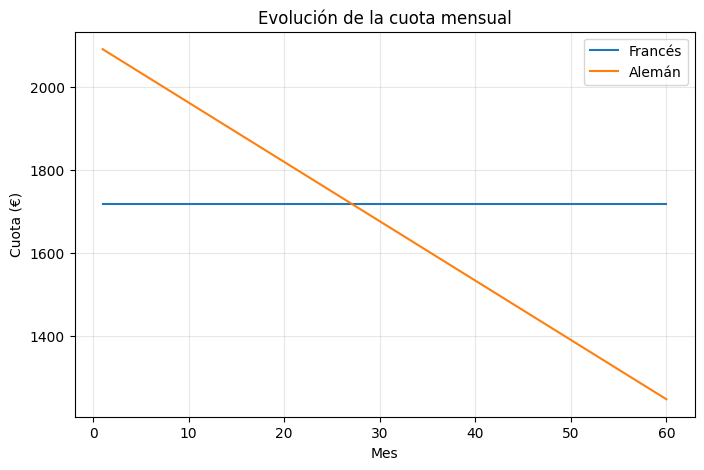

In [25]:
plt.figure(figsize=(8, 5))

plt.plot(grafico_frances["Periodo"], grafico_frances["Cuota"], label="Francés")
plt.plot(grafico_aleman["Periodo"], grafico_aleman["Cuota"], label="Alemán")

plt.title("Evolución de la cuota mensual")
plt.xlabel("Mes")
plt.ylabel("Cuota (€)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

En este primer gráfico se observa que en el préstamo de ejemplo, la cuota francesa se mantiene constante. La alemana empieza siendo más alta, pero va bajando y acaba siendo menor.


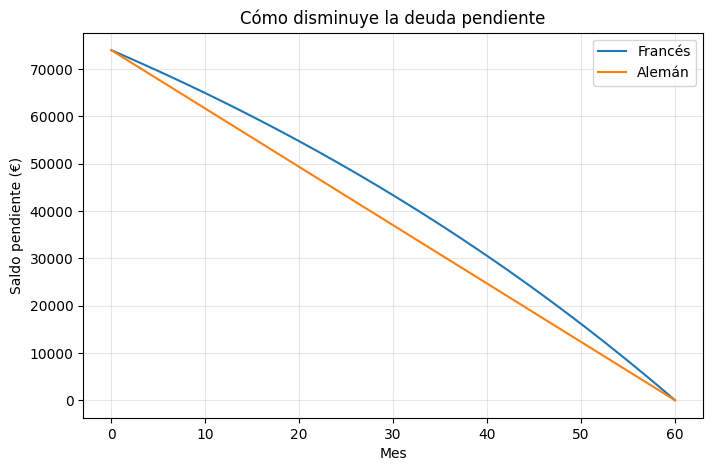

In [26]:
meses_frances = [0] + grafico_frances["Periodo"].tolist()
meses_aleman = [0] + grafico_aleman["Periodo"].tolist()

saldo_frances = [prestamo_grafico["Monto_Inicial"]] + grafico_frances["Saldo_Pendiente"].tolist()
saldo_aleman = [prestamo_grafico["Monto_Inicial"]] + grafico_aleman["Saldo_Pendiente"].tolist()

plt.figure(figsize=(8, 5))

plt.plot(meses_frances, saldo_frances, label="Francés")
plt.plot(meses_aleman, saldo_aleman, label="Alemán")

plt.title("Cómo disminuye la deuda pendiente")
plt.xlabel("Mes")
plt.ylabel("Saldo pendiente (€)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

En este gráfico se observa que con el sistema alemán, la deuda pendiente disminuye más rápido. En ambos sistemas, queda pagada al llegar al mes 60.


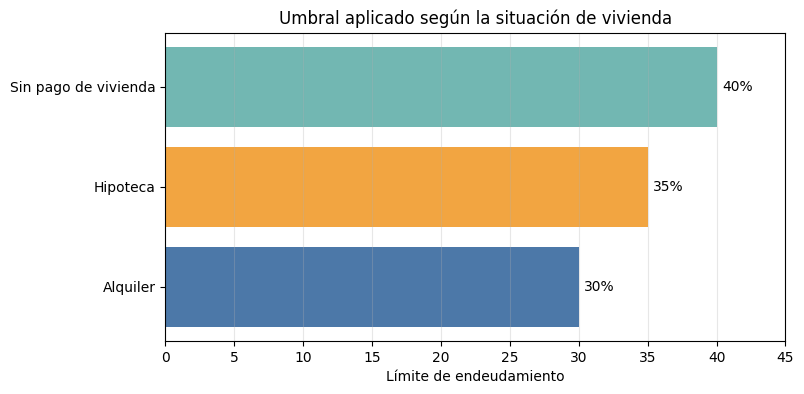

In [27]:
orden = [
    "Alquiler asumido",
    "Hipoteca",
    "Sin pago de vivienda asumido"
]

limites = (
    df.groupby("Situacion_vivienda")["Limite_liquidez"]
    .first()
    .reindex(orden) * 100
)

nombres = ["Alquiler", "Hipoteca", "Sin pago de vivienda"]

plt.figure(figsize=(8, 4))
barras = plt.barh(nombres, limites.values, color=["#4C78A8", "#F2A541", "#72B7B2"])

plt.bar_label(barras, fmt="%.0f%%", padding=4)
plt.xlim(0, 45)
plt.xlabel("Límite de endeudamiento")
plt.title("Umbral aplicado según la situación de vivienda")
plt.grid(axis="x", alpha=0.3)
plt.show()

Este último gráfico muestra los límites que usamos según la vivienda: 30 % con alquiler, 35 % con hipoteca y 40 % sin pago de vivienda. Son criterios del modelo.

In [28]:
df.drop(columns="Justificacion", errors="ignore").to_csv("resultados_amortizacion_educacion.csv", index=False)